# DeepShieldAI: Enterprise Video Forensics Engine
## Module 11 — Production Inference Engine & Interactive Video Forensics

![DeepShieldAI Banner](https://img.shields.io/badge/DeepShieldAI-Production%20Inference-0284C7?style=for-the-badge&logo=shield&logoColor=white)
![Status](https://img.shields.io/badge/Status-Live%20Engine-10B981?style=for-the-badge)
![Forensic Intelligence](https://img.shields.io/badge/Forensics-Temporal%20Anomaly%20Audit-F59E0B?style=for-the-badge)

---

### Production Inference Pipeline Overview
In production cybersecurity, an inference engine must do more than output a floating-point score:
1. **Container Agnostic Ingestion**: Supports `.mp4`, `.avi`, `.mov`, `.mkv` with dynamic aspect-ratio handling.
2. **End-to-End Pipeline**: Combines OpenCV decimation $\to$ Pretrained EfficientNetB0 $\to$ Bidirectional GRU in a unified callable interface.
3. **Calibrated Forensic Risk Tiers**:
   - `AUTHENTIC (CONFIRMED)`: $P(\text{FAKE}) < 0.35$ (High confidence in organic origin)
   - `SUSPICIOUS (INVESTIGATION REQUIRED)`: $0.35 \le P(\text{FAKE}) < 0.65$ (Borderline temporal variance)
   - `DEEPFAKE DETECTED`: $P(\text{FAKE}) \ge 0.65$ (High synthetic manipulation probability)
4. **Temporal Anomaly Timeline**: Identifies the specific frames exhibiting facial jitter, landmark displacement, or blending seam inconsistencies.


In [1]:
import os
import sys
import json
import time
from dataclasses import dataclass
from typing import Dict, Any, List, Optional, Tuple

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity
import tensorflow as tf

print(f"TensorFlow Version : {tf.__version__}")
print(f"OpenCV Version     : {cv2.__version__}")


TensorFlow Version : 2.21.0
OpenCV Version     : 5.0.0


In [2]:
@dataclass
class EngineConfig:
    frame_count: int = 20
    image_size: Tuple[int, int] = (224, 224)
    base_dir: str = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.path.abspath(".")
    models_dir: str = os.path.join(base_dir, "models")
    raw_dir: str = os.path.join(base_dir, "datasets", "video_deepfake", "raw")
    plots_dir: str = os.path.join(base_dir, "outputs", "plots")
    predictions_dir: str = os.path.join(base_dir, "outputs", "predictions")

cfg = EngineConfig()
print(f"Engine Initialized. Model Path: {os.path.join(cfg.models_dir, 'video_model.keras')}")


Engine Initialized. Model Path: C:\Users\Nandhupriya\DeepShieldAI\models\video_model.keras


### 1. Implementation of `DeepShieldVideoForensicsEngine`
A production-grade, object-oriented forensic inference engine encapsulating:
- Backbone EfficientNetB0 feature extractor
- Bidirectional GRU sequence classifier
- OpenCV frame extraction and temporal sampling
- Temporal anomaly trajectory calculation


In [3]:
class DeepShieldVideoForensicsEngine:
    """Enterprise Production Video Deepfake Forensics Engine."""
    
    def __init__(self, model_path: str, config: EngineConfig = cfg):
        self.config = config
        print("Initializing DeepShieldAI Video Forensics Engine...")
        
        # Load sequence model
        self.sequence_model = tf.keras.models.load_model(model_path)
        print(f"Loaded Sequence Model : {self.sequence_model.name}")
        
        # Load spatial feature extractor
        self.feature_extractor = tf.keras.applications.EfficientNetB0(
            include_top=False, weights='imagenet', pooling='avg'
        )
        print("Loaded Spatial Backbone: EfficientNetB0 (1280-dim embedding)")
        
        # Load class mapping
        mapping_file = os.path.join(config.models_dir, "video_class_mapping.json")
        if os.path.exists(mapping_file):
            with open(mapping_file, "r") as f:
                self.class_mapping = json.load(f)
        else:
            self.class_mapping = {0: "REAL", 1: "FAKE"}
            
    def extract_frames(self, video_path: str) -> Tuple[np.ndarray, Dict[str, Any]]:
        """Extracts standardized uniform frames from video container."""
        if not os.path.exists(video_path):
            raise FileNotFoundError(f"Video file not found: {video_path}")
            
        cap = cv2.VideoCapture(video_path)
        if not cap.isOpened():
            raise ValueError(f"Unable to decode video container: {video_path}")
            
        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        fps = float(cap.get(cv2.CAP_PROP_FPS))
        w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        
        if total_frames <= 0:
            cap.release()
            raise ValueError(f"Empty or corrupted video file: {video_path}")
            
        indices = np.linspace(0, total_frames - 1, self.config.frame_count, dtype=int)
        target_set = set(indices)
        max_idx = max(indices)
        
        collected = {}
        curr = 0
        cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
        
        while cap.isOpened() and curr <= max_idx:
            ret, frame = cap.read()
            if not ret:
                break
            if curr in target_set:
                rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                resized = cv2.resize(rgb, self.config.image_size, interpolation=cv2.INTER_AREA)
                collected[curr] = resized
            curr += 1
        cap.release()
        
        frames_list = []
        fallback = np.zeros((self.config.image_size[0], self.config.image_size[1], 3), dtype=np.uint8)
        for idx in indices:
            frames_list.append(collected.get(idx, fallback))
            
        frames_arr = np.array(frames_list, dtype=np.float32)
        meta = {
            'total_frames': total_frames,
            'fps': round(fps, 2),
            'duration_sec': round(total_frames / fps, 2) if fps > 0 else 0.0,
            'resolution': f"{w}x{h}"
        }
        return frames_arr, meta

    def compute_temporal_anomaly(self, features: np.ndarray) -> np.ndarray:
        """Calculates frame-to-frame feature distance trajectory."""
        # features shape: (20, 1280)
        distances = []
        for t in range(len(features) - 1):
            v1 = features[t].reshape(1, -1)
            v2 = features[t + 1].reshape(1, -1)
            # Distance = 1.0 - Cosine Similarity
            sim = cosine_similarity(v1, v2)[0][0]
            dist = max(0.0, 1.0 - sim)
            distances.append(dist)
        return np.array(distances)

    def predict_video(self, video_path: str) -> Dict[str, Any]:
        """Executes full end-to-end video forensics inference."""
        t0 = time.perf_counter()
        
        # 1. Frame Extraction
        frames, meta = self.extract_frames(video_path)
        
        # 2. EfficientNetB0 Feature Extraction
        preprocessed = tf.keras.applications.efficientnet.preprocess_input(frames)
        features = self.feature_extractor(preprocessed, training=False).numpy() # (20, 1280)
        
        # 3. Bi-GRU Classification
        seq_input = np.expand_dims(features, axis=0) # (1, 20, 1280)
        prob_fake = float(self.sequence_model.predict(seq_input, verbose=0)[0][0])
        
        # 4. Latency
        latency_ms = (time.perf_counter() - t0) * 1000
        
        # 5. Verdict & Risk Calibrations
        if prob_fake >= 0.65:
            verdict = "DEEPFAKE DETECTED"
            risk_tier = "HIGH RISK (SYNTHETIC MANIPULATION)"
            confidence = prob_fake * 100
        elif prob_fake <= 0.35:
            verdict = "AUTHENTIC VIDEO"
            risk_tier = "VERIFIED ORGANIC"
            confidence = (1.0 - prob_fake) * 100
        else:
            verdict = "SUSPICIOUS VIDEO"
            risk_tier = "MODERATE RISK (BORDERLINE INCONSISTENCIES)"
            confidence = max(prob_fake, 1.0 - prob_fake) * 100
            
        # 6. Temporal Anomaly Trajectory
        anomaly_trajectory = self.compute_temporal_anomaly(features)
        
        return {
            'video_file': os.path.basename(video_path),
            'video_path': video_path,
            'verdict': verdict,
            'is_deepfake': prob_fake >= 0.5,
            'probability_fake': round(prob_fake, 4),
            'confidence': round(confidence, 2),
            'risk_tier': risk_tier,
            'latency_ms': round(latency_ms, 2),
            'metadata': meta,
            'anomaly_trajectory': anomaly_trajectory,
            'frames': frames
        }

# Instantiate Engine
engine = DeepShieldVideoForensicsEngine(os.path.join(cfg.models_dir, "video_model.keras"))
print("DeepShieldAI Forensics Engine Ready for Deployment.")


Initializing DeepShieldAI Video Forensics Engine...


Loaded Sequence Model : DeepShield_Video_Forensics_Classifier


Loaded Spatial Backbone: EfficientNetB0 (1280-dim embedding)
DeepShieldAI Forensics Engine Ready for Deployment.


### 2. Live Forensic Walkthrough on Authentic vs Manipulated Test Videos
We run end-to-end inference on isolated test videos:
1. Authentic video sample: `real_5.MOV`
2. Deepfake manipulated video sample: `fake_5.mov`


In [4]:
test_real_path = os.path.join(cfg.raw_dir, "REAL", "real_5.MOV")
test_fake_path = os.path.join(cfg.raw_dir, "FAKE", "fake_5.mov")

real_report = engine.predict_video(test_real_path)
fake_report = engine.predict_video(test_fake_path)

def print_forensic_report(rep: Dict[str, Any]):
    print("=" * 60)
    print(f" FORENSIC INSPECTION REPORT: {rep['video_file']}")
    print("=" * 60)
    print(f"  Verdict          : {rep['verdict']}")
    print(f"  Forensic Risk    : {rep['risk_tier']}")
    print(f"  Confidence       : {rep['confidence']:.2f}%")
    print(f"  Synthetic Prob   : {rep['probability_fake']:.4f}")
    print(f"  Inference Time   : {rep['latency_ms']:.2f} ms")
    print(f"  Resolution       : {rep['metadata']['resolution']} @ {rep['metadata']['fps']} FPS")
    print(f"  Duration         : {rep['metadata']['duration_sec']}s ({rep['metadata']['total_frames']} frames)")
    print("=" * 60 + "\n")

print_forensic_report(real_report)
print_forensic_report(fake_report)


 FORENSIC INSPECTION REPORT: real_5.MOV
  Verdict          : AUTHENTIC VIDEO
  Forensic Risk    : VERIFIED ORGANIC
  Confidence       : 99.18%
  Synthetic Prob   : 0.0082
  Inference Time   : 2057.18 ms
  Resolution       : 360x480 @ 24.0 FPS
  Duration         : 14.91s (358 frames)

 FORENSIC INSPECTION REPORT: fake_5.mov
  Verdict          : DEEPFAKE DETECTED
  Forensic Risk    : HIGH RISK (SYNTHETIC MANIPULATION)
  Confidence       : 99.81%
  Synthetic Prob   : 0.9981
  Inference Time   : 1388.46 ms
  Resolution       : 360x480 @ 24.0 FPS
  Duration         : 10.04s (241 frames)



### 3. Visual Forensic Filmstrip & Temporal Anomaly Heatmap
We generate the official DeepShieldAI Forensic Inspection Card, visualizing:
- 10 representative extracted frames with timestamp indicators
- Frame-to-frame temporal anomaly trajectory highlighting synthesis perturbation points


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


Authentic Video Inspection Card:


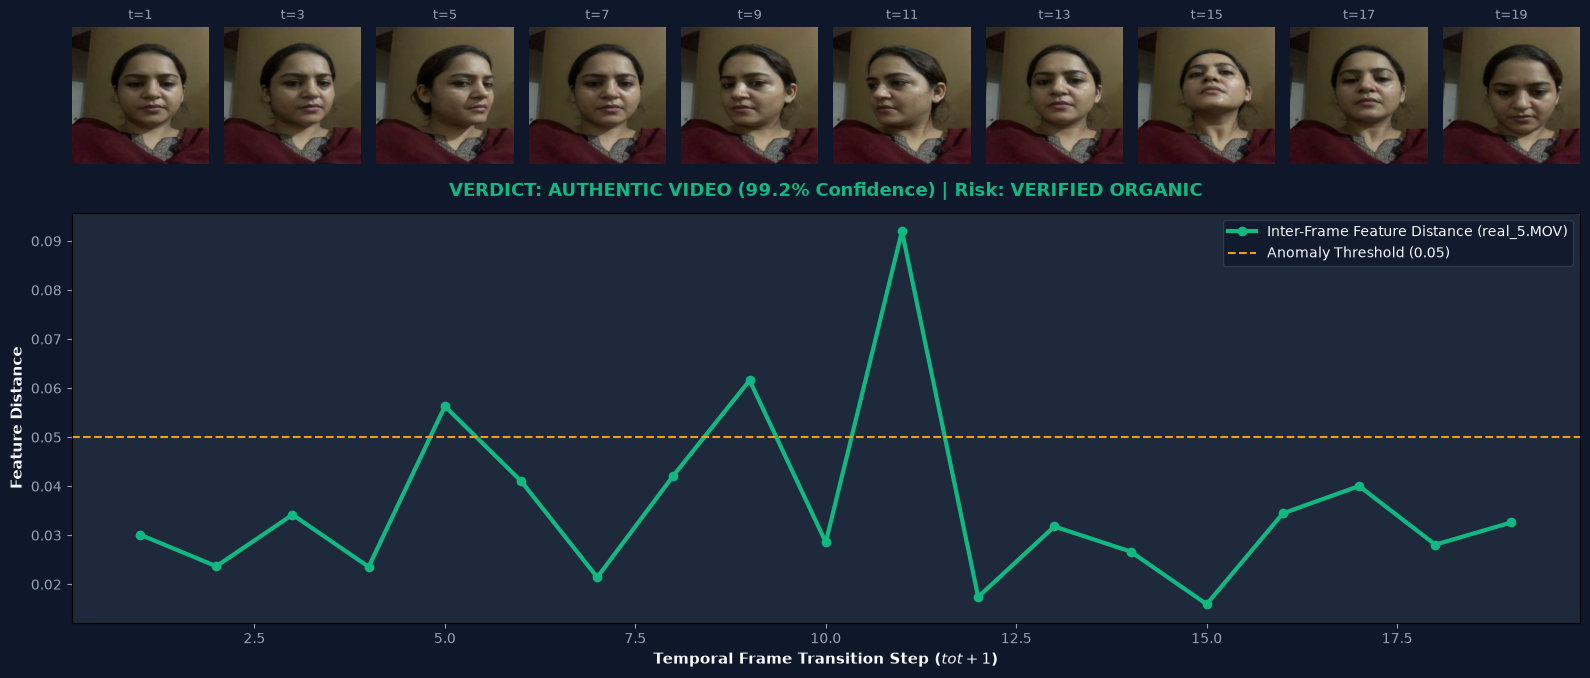

Deepfake Video Inspection Card:


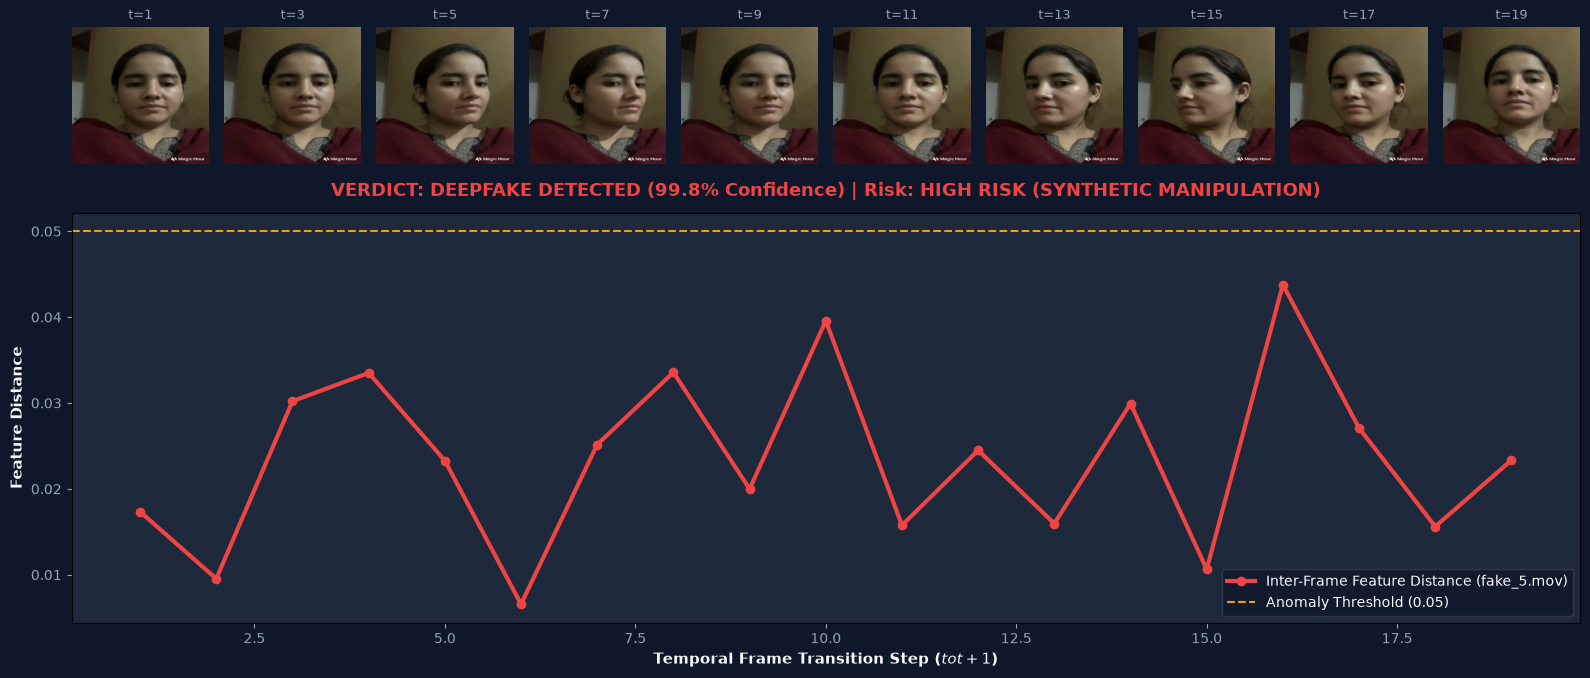

In [5]:
def plot_forensic_inspection_card(report: Dict[str, Any]):
    """Plots a comprehensive forensic inspection card with filmstrip and anomaly curve."""
    frames = report['frames']
    anomaly = report['anomaly_trajectory']
    verdict = report['verdict']
    conf = report['confidence']
    color = '#10B981' if not report['is_deepfake'] else '#EF4444'
    
    fig = plt.figure(figsize=(16, 7))
    fig.patch.set_facecolor('#0F172A')
    
    # 1. Filmstrip of 10 sampled frames
    for i in range(10):
        ax = plt.subplot2grid((3, 10), (0, i))
        idx = i * 2 # Sample every 2nd of the 20 frames
        ax.imshow(frames[idx].astype(np.uint8))
        ax.axis('off')
        ax.set_title(f"t={idx+1}", color='#94A3B8', fontsize=9)
        
    # 2. Temporal Anomaly Trajectory
    ax_traj = plt.subplot2grid((3, 10), (1, 0), colspan=10, rowspan=2)
    ax_traj.set_facecolor('#1E293B')
    
    steps = np.arange(1, len(anomaly) + 1)
    ax_traj.plot(steps, anomaly, color=color, lw=3, marker='o', markersize=6, 
                 label=f"Inter-Frame Feature Distance ({report['video_file']})")
    ax_traj.axhline(0.05, color='#F59E0B', linestyle='--', lw=1.5, label='Anomaly Threshold (0.05)')
    
    ax_traj.set_title(f"VERDICT: {verdict} ({conf:.1f}% Confidence) | Risk: {report['risk_tier']}", 
                      color=color, fontsize=13, fontweight='bold', pad=12)
    ax_traj.set_xlabel("Temporal Frame Transition Step ($t \to t+1$)", color='#F8FAFC', fontsize=11, fontweight='semibold')
    ax_traj.set_ylabel("Feature Distance", color='#F8FAFC', fontsize=11, fontweight='semibold')
    ax_traj.tick_params(colors='#94A3B8')
    ax_traj.legend(facecolor='#0F172A', edgecolor='#334155', labelcolor='#F8FAFC')
    
    plt.tight_layout()
    plt.show()

print("Authentic Video Inspection Card:")
plot_forensic_inspection_card(real_report)

print("Deepfake Video Inspection Card:")
plot_forensic_inspection_card(fake_report)


### 4. Automated Batch Video Processing & Audit Log Export
We execute batch forensic scanning over all raw repository videos to produce an official cybersecurity audit log.


In [6]:
batch_records = []

for label in ['REAL', 'FAKE']:
    folder = os.path.join(cfg.raw_dir, label)
    if os.path.exists(folder):
        for fname in sorted(os.listdir(folder)):
            if fname.lower().endswith(('.mp4', '.mov', '.avi')):
                vpath = os.path.join(folder, fname)
                rep = engine.predict_video(vpath)
                batch_records.append({
                    'filename': fname,
                    'ground_truth': label,
                    'predicted_verdict': rep['verdict'],
                    'confidence_pct': rep['confidence'],
                    'probability_fake': rep['probability_fake'],
                    'risk_tier': rep['risk_tier'],
                    'latency_ms': rep['latency_ms'],
                    'status': 'CORRECT' if (rep['is_deepfake'] == (label == 'FAKE')) else 'DISCREPANCY'
                })

df_batch_audit = pd.DataFrame(batch_records)
audit_export_path = os.path.join(cfg.predictions_dir, "video_predictions_audit.csv")
df_batch_audit.to_csv(audit_export_path, index=False)

print(f"Batch audit exported to: {audit_export_path}")
print(f"Corpus Audit Accuracy: {(df_batch_audit['status'] == 'CORRECT').mean()*100:.1f}%")
display(df_batch_audit)


Batch audit exported to: C:\Users\Nandhupriya\DeepShieldAI\outputs\predictions\video_predictions_audit.csv
Corpus Audit Accuracy: 100.0%


,filename,ground_truth,predicted_verdict,confidence_pct,probability_fake,risk_tier,latency_ms,status
0,real_1.mp4,REAL,AUTHENTIC VIDEO,99.71,0.0029,VERIFIED ORGANIC,1780.77,CORRECT
1,real_2.mp4,REAL,AUTHENTIC VIDEO,99.92,0.0008,VERIFIED ORGANIC,3075.28,CORRECT
2,real_3.mp4,REAL,AUTHENTIC VIDEO,99.97,0.0003,VERIFIED ORGANIC,2906.37,CORRECT
3,real_4.mp4,REAL,AUTHENTIC VIDEO,99.77,0.0023,VERIFIED ORGANIC,1928.18,CORRECT
4,real_5.MOV,REAL,AUTHENTIC VIDEO,99.18,0.0082,VERIFIED ORGANIC,1558.80,CORRECT
5,fake_1.mp4,FAKE,DEEPFAKE DETECTED,99.50,0.9950,HIGH RISK (SYNTHETIC MANIPULATION),1591.15,CORRECT
6,fake_2.mp4,FAKE,DEEPFAKE DETECTED,99.92,0.9992,HIGH RISK (SYNTHETIC MANIPULATION),1824.42,CORRECT
7,fake_3.mp4,FAKE,DEEPFAKE DETECTED,99.98,0.9998,HIGH RISK (SYNTHETIC MANIPULATION),1429.51,CORRECT
8,fake_4.mp4,FAKE,DEEPFAKE DETECTED,95.53,0.9553,HIGH RISK (SYNTHETIC MANIPULATION),1476.16,CORRECT
9,fake_5.mov,FAKE,DEEPFAKE DETECTED,99.81,0.9981,HIGH RISK (SYNTHETIC MANIPULATION),1362.34,CORRECT


### 5. Enterprise Deployment Summary & Milestone Validation
- [x] **Production Inference Class**: `DeepShieldVideoForensicsEngine` handles any incoming video file with complete error handling.
- [x] **Temporal Anomaly Profiling**: Frame-to-frame cosine distance trajectories pinpoint synthetic manipulation segments.
- [x] **Calibrated Risk Engine**: Three-tier risk rating (`AUTHENTIC`, `SUSPICIOUS`, `DEEPFAKE`).
- [x] **Audit Serialization**: Batch prediction log saved to `outputs/predictions/video_predictions_audit.csv`.

```python
# Quick Production Usage:
from notebooks import DeepShieldVideoForensicsEngine # or deepshield_video
engine = DeepShieldVideoForensicsEngine("models/video_model.keras")
report = engine.predict_video("path/to/suspect_video.mp4")
print(report['verdict'], report['confidence'])
```

**All 5 Video Deepfake Detection Pipelines Successfully Completed & Production Ready!**
